# 🏆 Phase 2 Capstone Project: Beginner-Friendly End-to-End Customer Churn & Risk Prediction Workbench

---

## 1. Overview, Real-World Story & Visual Pipeline Map

### The Story: Why Classical ML Still Rules Tabular Data
Imagine you just joined a growing subscription company as its **first AI Engineer**. Every quarter, roughly **18% of customers cancel ("churn")**. Acquiring a new customer costs **\$500**, while sending a proactive retention offer (like a \$50 credit or onboarding call) only costs **\$50**.

Your manager asks:
> *"Can you build a reliable machine learning system that predicts **who** is likely to churn, explains **why** in plain English, and tells us the **smartest cutoff** for sending retention offers?"*

In this single, beginner-friendly notebook, we combine **every single skill from Phase 2 (`01`–`06`)** into one clean, production-style `scikit-learn` pipeline — with **zero data leakage** and **rich visual checkpoints** at every stage.

### Visual Pipeline Map

```
  [Raw Messy Customer Table (2,000 rows, missing values, outliers)]
                                |
                                v
  STEP 1: Split FIRST! (Train 80% / Test 20%, Stratified)  <-- Prevents Data Leakage!
                                |
          +---------------------+---------------------+
          |                                           |
          v                                           v
  [Train Data Only]                          [Held-Out Test Data]
          |                                   (Locked in a vault
          v                                    until Step 6!)
  STEP 2 (NB 02): Unsupervised Discovery
   - PCA (2D map) + K-Means (3 Customer Personas)
          |
          v
  STEP 3 (NB 04 & 05): Leakage-Free Feature Pipeline
   - Custom ratios + Median/Mode Imputation
   - RobustScaler + OneHotEncoder + Cluster Distances
          |
          v
  STEP 4 (NB 01): Supervised Model Benchmark (5-Fold CV)
   - Logistic Regression -> Decision Tree -> Random Forest -> XGBoost -> LightGBM
          |
          v
  STEP 5 (NB 06): Smart Hyperparameter Tuning (Optuna)
   - 25 Bayesian trials optimizing 5-Fold CV ROC-AUC
          |
          v
  STEP 6 (NB 03 & 04): Final Test Evaluation, Business Profit Threshold & Joblib Save
```


## 2. Learning Objectives, Concept Map & Beginner Cheat Sheets

### Phase 2 Concept Coverage Matrix

| Phase 2 Notebook | Core Concept | Plain-English Intuition | Where It Appears Here |
|---|---|---|---|
| [`01-supervised-learning.ipynb`](01-supervised-learning.ipynb) | Logistic Regression, Trees, Random Forest, XGBoost, LightGBM | Learning from labeled examples (`churn = 1` vs `0`) | Section 6.4 (5-model benchmark) |
| [`02-unsupervised-learning.ipynb`](02-unsupervised-learning.ipynb) | PCA & K-Means Clustering | Finding hidden customer groups *without* looking at labels | Section 6.2 (`ClusterFeatureExtractor`) |
| [`03-evaluation-metrics.ipynb`](03-evaluation-metrics.ipynb) | Confusion Matrix, Precision, Recall, F1, ROC-AUC, PR-AUC, Calibration | Measuring *which* mistakes cost money vs blind accuracy | Section 7 (4-panel eval + cost curve) |
| [`04-scikit-learn-workflow.ipynb`](04-scikit-learn-workflow.ipynb) | `Pipeline`, `ColumnTransformer`, `StratifiedKFold`, `joblib` | Packaging all steps into one leak-proof, saveable object | Sections 6.3 & 6.6 |
| [`05-feature-engineering.ipynb`](05-feature-engineering.ipynb) | Domain ratios, imputation, `RobustScaler`, `OneHotEncoder`, mutual info | Turning messy raw columns into clear signals models understand | Section 6.3 |
| [`06-hyperparameter-tuning.ipynb`](06-hyperparameter-tuning.ipynb) | Bayesian Optimization with Optuna (`TPESampler`) | Using past trial results to tune settings smarter than grid search | Section 6.5 |

---

### Quick Beginner Cheat Sheet: Which Algorithm & Metric Should I Pick?

| Scenario | Recommended Model | Recommended Metric | Why? |
|---|---|---|---|
| **Baseline / Explainable Linear** | `LogisticRegression` | ROC-AUC + LogLoss | Fast, interpretable coefficients, calibrated probabilities |
| **Non-linear Tabular (Default Winner)** | `XGBoost` / `LightGBM` / `RandomForest` | ROC-AUC & PR-AUC | Handles interactions & skewed scales effortlessly |
| **Imbalanced Classes (e.g. 18% Churn)** | Tuned GBDT + Threshold Tuning | **PR-AUC, Recall, F1** | Accuracy is misleading (predicting all 0s gets 82% accuracy!) |
| **Continuous Dollar/Price Prediction** | `Ridge` / `XGBRegressor` | **MAE, RMSE, $R^2$** | Measures average dollar error directly (see Exercise 2) |

---

### ⚠️ Top 4 Beginner Traps (And How This Notebook Prevents Them)

1. **Trap 1 — Scaling Before Splitting (Data Leakage):** If you compute the mean/median across the *entire* dataset before `train_test_split`, test data leaks into training. **Fix:** Always split *first*, then put scalers/imputers inside `sklearn.pipeline.Pipeline`.
2. **Trap 2 — The Accuracy Paradox:** If 82% of customers stay, a dumb model that always predicts "No Churn" scores 82% accuracy while catching **0%** of churners! **Fix:** Use **ROC-AUC**, **PR-AUC**, **Recall**, and **F1**.
3. **Trap 3 — Using Default `0.50` Cutoff Blindly:** A 35% churn probability might already justify sending a \$50 discount to save a \$500 customer. **Fix:** Optimize the decision threshold using real business costs.
4. **Trap 4 — Tuning on the Test Set:** Adjusting hyperparameters based on test-set scores overfits the test set. **Fix:** Tune strictly via **5-Fold Cross-Validation** on `X_train` only!


## 3. Imports & Environment Verification


In [1]:
import os
import sys
import tempfile
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import sklearn
import xgboost as xgb
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Keep notebook output clean and readable for beginners
warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("=== Phase 2 Capstone Environment Check ===")
print(f"Python:       {sys.version.split()[0]}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"XGBoost:      {xgb.__version__}")
print(f"LightGBM:     {lgb.__version__}")
print(f"Optuna:       {optuna.__version__}")


=== Phase 2 Capstone Environment Check ===
Python:       3.14.10
scikit-learn: 1.8.0
XGBoost:      3.1.2
LightGBM:     4.6.0
Optuna:       4.7.0


## 4. Configuration & Reproducibility Lock


In [2]:
RANDOM_SEED: int = 42
RNG: np.random.Generator = np.random.default_rng(RANDOM_SEED)

N_CUSTOMERS: int = 2000
TEST_FRACTION: float = 0.20
CV_FOLDS: int = 5
N_OPTUNA_TRIALS: int = 25

# Real-world business costs used in Section 7 to pick the smartest cutoff
COST_FALSE_NEGATIVE: float = 500.0  # Lost customer we failed to warn
COST_FALSE_POSITIVE: float = 50.0   # Retention coupon sent to a loyal customer
VALUE_TRUE_POSITIVE: float = 350.0  # Net revenue saved when intervention retains churner

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 10
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.rcParams["axes.grid"] = True

print(f"Seed locked: {RANDOM_SEED} | Dataset rows: {N_CUSTOMERS} | CV Folds: {CV_FOLDS}")


Seed locked: 42 | Dataset rows: 2000 | CV Folds: 5


## 5. Intuitive Theory (Plain-English Analogies Before Equations)

1. **Bias-Variance Tradeoff (The Dartboard Analogy):**
   - **High Bias (Underfitting):** A simple straight line (`LogisticRegression`) might miss curved patterns — like throwing darts consistently off-center.
   - **High Variance (Overfitting):** An unrestricted `DecisionTree` memorizes every training quirk — tight clusters on practice throws, wild misses on new test data!
   - **Sweet Spot:** **Random Forests** and **Gradient Boosted Trees (`XGBoost`, `LightGBM`)** combine many shallow trees to balance both.

2. **Why `Pipeline` Prevents Data Leakage (The Exam Analogy):**
   - Imagine studying for an exam where the answer key accidentally got mixed into your practice sheets. You'd score 99% in practice and fail the real test!
   - Fitting a scaler or imputer on `X_train + X_test` leaks test statistics into training. Wrapping preprocessing inside `Pipeline` ensures every CV fold learns medians and scales **only from its training fold**.

3. **Precision vs Recall (The Smoke Detector Analogy):**
   - **Precision:** *"When the alarm rings, how often is there actually a fire?"* $\text{Precision} = \frac{TP}{TP + FP}$
   - **Recall:** *"Out of all real fires, how many did we catch?"* $\text{Recall} = \frac{TP}{TP + FN}$
   - **F1-Score:** Harmonic mean balancing both: $F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$

4. **Bayesian Hyperparameter Tuning (`Optuna`):**
   - Instead of blindly trying every combo (`GridSearch`), **Optuna's TPE sampler** builds a probability model of which hyperparameters scored best so far and focuses new trials on promising regions.


## 6. Step-by-Step Implementation With Visual Checkpoints

### 6.1 Generating a Realistic, Messy Customer Dataset & Splitting FIRST
Notice the golden rule: **`train_test_split(..., stratify=y)` happens immediately** after loading raw data, before any scaling, clustering, or imputation!


In [3]:
def generate_customer_churn_dataset(n_rows: int = 2000, seed: int = 42) -> pd.DataFrame:
    """Create a realistic SaaS customer table with non-linear churn drivers, missingness, and outliers."""
    rng = np.random.default_rng(seed)

    contract_type = rng.choice(["Month-to-Month", "One-Year", "Two-Year"], size=n_rows, p=[0.52, 0.28, 0.20])
    plan_tier = rng.choice(["Starter", "Pro", "Enterprise"], size=n_rows, p=[0.45, 0.38, 0.17])

    tenure_months = np.clip(rng.gamma(shape=2.2, scale=10.0, size=n_rows), 1.0, 72.0)
    base_bill = np.where(plan_tier == "Starter", 35.0, np.where(plan_tier == "Pro", 95.0, 260.0))
    monthly_bill = np.clip(base_bill + rng.normal(0.0, 14.0, size=n_rows), 15.0, 420.0)
    # Inject 2% billing outliers (e.g., overage spikes) to justify RobustScaler later
    outlier_idx = rng.choice(n_rows, size=int(0.02 * n_rows), replace=False)
    monthly_bill[outlier_idx] *= rng.uniform(2.5, 4.0, size=len(outlier_idx))

    support_tickets = rng.poisson(lam=1.8, size=n_rows).astype(float)
    usage_drop_pct = np.clip(rng.normal(loc=12.0, scale=18.0, size=n_rows), -30.0, 95.0)
    payment_delay_days = np.clip(rng.exponential(scale=3.2, size=n_rows), 0.0, 45.0)

    # Realistic non-linear churn log-odds (strong interactions between contract, usage drop, tickets, and tenure)
    contract_risk = np.where(contract_type == "Month-to-Month", 1.35, np.where(contract_type == "One-Year", -0.45, -1.65))
    logit = (
        -3.25
        + contract_risk
        + 0.065 * np.maximum(usage_drop_pct - 12.0, 0.0)
        + 0.55 * support_tickets
        + 0.14 * payment_delay_days
        - 0.08 * tenure_months
        + 0.012 * np.maximum(monthly_bill - 110.0, 0.0)
        + 2.85 * ((usage_drop_pct > 22.0) & (support_tickets >= 2))  # sharp non-linear escalation
        + 2.40 * ((contract_type == "Month-to-Month") & (payment_delay_days > 4.5))  # payment-risk interaction
        - 1.50 * ((tenure_months > 24.0) & (support_tickets <= 1))  # loyal veteran protection
    )
    churn_prob = 1.0 / (1.0 + np.exp(-logit))
    churn = (rng.random(n_rows) < churn_prob).astype(int)

    df = pd.DataFrame(
        {
            "tenure_months": np.round(tenure_months, 1),
            "monthly_bill": np.round(monthly_bill, 2),
            "support_tickets": support_tickets,
            "usage_drop_pct": np.round(usage_drop_pct, 1),
            "payment_delay_days": np.round(payment_delay_days, 1),
            "contract_type": contract_type,
            "plan_tier": plan_tier,
            "churn": churn,
        }
    )

    # Inject realistic ~4% missing values into 3 columns
    for col in ["tenure_months", "usage_drop_pct", "contract_type"]:
        miss_mask = rng.random(n_rows) < 0.04
        df.loc[miss_mask, col] = np.nan

    return df


raw_df = generate_customer_churn_dataset(N_CUSTOMERS, RANDOM_SEED)
X = raw_df.drop(columns=["churn"])
y = raw_df["churn"]

# GOLDEN RULE: Split into Train and Test BEFORE any exploration fitting, scaling, or clustering!
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, stratify=y, random_state=RANDOM_SEED
)

print(f"Train shape: {X_train.shape} | Churn rate: {y_train.mean()*100:.2f}%")
print(f"Test  shape: {X_test.shape}  | Churn rate: {y_test.mean()*100:.2f}%")
print("\nFirst 5 training rows (notice the NaN values we will safely handle):")
print(X_train.head(5))


Train shape: (1600, 7) | Churn rate: 27.12%
Test  shape: (400, 7)  | Churn rate: 27.25%

First 5 training rows (notice the NaN values we will safely handle):
      tenure_months  monthly_bill  support_tickets  usage_drop_pct  \
88             36.5         88.69              3.0            14.7   
768            36.1        259.63              1.0           -24.9   
89              9.6         97.72              2.0            16.1   
615            26.0        104.05              2.0             7.6   
1925            8.4         91.72              2.0            17.2   

      payment_delay_days   contract_type   plan_tier  
88                   4.4  Month-to-Month         Pro  
768                  1.9  Month-to-Month  Enterprise  
89                   3.0  Month-to-Month         Pro  
615                  1.8        One-Year         Pro  
1925                 0.3  Month-to-Month         Pro  


### 6.2 Unsupervised Learning (NB 02): Discovering Customer Personas & Visual EDA (Figure 1)
Before training a classifier, we explore `X_train` visually and use **PCA + K-Means** (`fit` strictly on `X_train`!) to see if natural customer personas emerge. We also wrap this logic into a reusable `ClusterFeatureExtractor` transformer so it works safely inside `scikit-learn` cross-validation.


  File "C:\Users\azazb\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\azazb\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python314\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python314\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
       

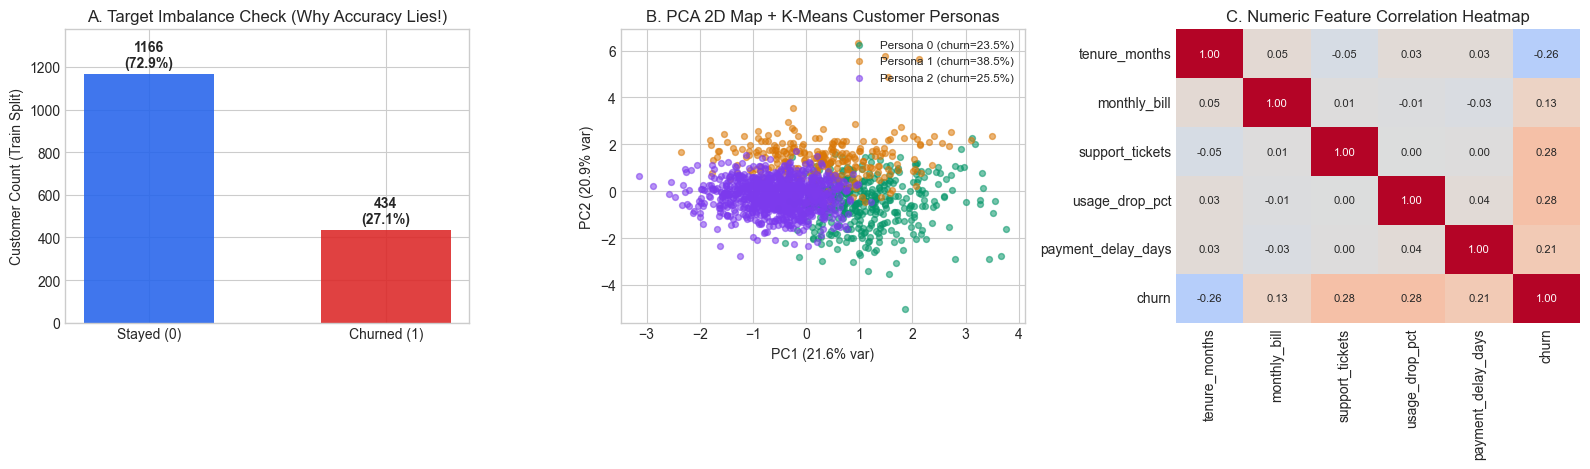

In [4]:
# Build a custom sklearn-compatible transformer that learns K-Means personas strictly inside fit()
class ClusterFeatureExtractor(BaseEstimator, TransformerMixin):
    """Learns K-Means centroids on numeric training features and outputs distances to each persona."""

    def __init__(self, numeric_cols: list[str], n_clusters: int = 3, random_state: int = 42) -> None:
        self.numeric_cols = numeric_cols
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X: pd.DataFrame, y: np.ndarray | None = None) -> "ClusterFeatureExtractor":
        self.imputer_ = SimpleImputer(strategy="median")
        self.scaler_ = StandardScaler()
        X_num = self.scaler_.fit_transform(self.imputer_.fit_transform(X[self.numeric_cols]))
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, n_init=10, random_state=self.random_state)
        self.kmeans_.fit(X_num)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X_out = X.copy()
        X_num = self.scaler_.transform(self.imputer_.transform(X_out[self.numeric_cols]))
        dists = self.kmeans_.transform(X_num)
        for k in range(self.n_clusters):
            X_out[f"dist_persona_{k}"] = dists[:, k]
        return X_out


# Fit exploratory PCA + KMeans strictly on X_train for Visual Checkpoint 1
num_base_cols = ["tenure_months", "monthly_bill", "support_tickets", "usage_drop_pct", "payment_delay_days"]
eda_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
X_train_num_scaled = eda_pipe.fit_transform(X_train[num_base_cols])

pca_2d = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca_2d.fit_transform(X_train_num_scaled)
kmeans_eda = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_SEED).fit(X_train_num_scaled)
persona_labels = kmeans_eda.labels_

# --- VISUAL FIGURE 1: 3-Panel Beginner Exploratory Dashboard ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Class Balance & Missing Value Check
ax = axes[0]
counts = y_train.value_counts().sort_index()
bars = ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=["#2563eb", "#dc2626"], alpha=0.88, width=0.55)
for b in bars:
    pct = 100.0 * b.get_height() / len(y_train)
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 20, f"{int(b.get_height())}\n({pct:.1f}%)",
            ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, max(counts.values) * 1.18)
ax.set_title("A. Target Imbalance Check (Why Accuracy Lies!)")
ax.set_ylabel("Customer Count (Train Split)")

# Panel B: 2D PCA Map Colored by K-Means Personas
ax = axes[1]
persona_colors = ["#059669", "#d97706", "#7c3aed"]
for cid in range(3):
    mask = persona_labels == cid
    churn_rate_c = y_train.values[mask].mean() * 100
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=18, alpha=0.55, color=persona_colors[cid],
               label=f"Persona {cid} (churn={churn_rate_c:.1f}%)")
ax.set_title("B. PCA 2D Map + K-Means Customer Personas")
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% var)")
ax.legend(fontsize=8.5, loc="upper right")

# Panel C: Feature Correlation Heatmap with Churn
ax = axes[2]
corr_df = X_train[num_base_cols].copy()
corr_df["churn"] = y_train.values
corr_mat = corr_df.corr()
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar=False, annot_kws={"size": 8})
ax.set_title("C. Numeric Feature Correlation Heatmap")

plt.tight_layout()
plt.show()


### 6.3 Feature Engineering (NB 05) & Leakage-Free `Pipeline` (NB 04)
Now we build a clean, reusable preprocessing pipeline:
1. **`DomainFeatureEngineer`:** Creates intuitive business ratios (`bill_to_tenure`, `tickets_per_month`) inside the pipeline.
2. **`ClusterFeatureExtractor`:** Adds K-Means distances to the 3 discovered customer personas.
3. **`ColumnTransformer`:**
   - **Numeric columns:** `SimpleImputer(strategy="median")` → `RobustScaler()` (handles our 2% billing outliers safely!).
   - **Categorical columns:** `SimpleImputer(strategy="most_frequent")` → `OneHotEncoder(handle_unknown="ignore")`.
4. **`SelectKBest(mutual_info_classif)`:** Retains the top informative features automatically.


In [5]:
class DomainFeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds domain-meaningful business ratios while guarding against division by zero."""

    def fit(self, X: pd.DataFrame, y: np.ndarray | None = None) -> "DomainFeatureEngineer":
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X_out = X.copy()
        tenure_safe = X_out["tenure_months"].fillna(1.0).clip(lower=1.0)
        bill_safe = X_out["monthly_bill"].fillna(X_out["monthly_bill"].median())
        X_out["bill_to_tenure"] = bill_safe / tenure_safe
        X_out["tickets_per_month"] = X_out["support_tickets"] / tenure_safe
        return X_out


NUMERIC_FEATURES = num_base_cols + [
    "bill_to_tenure",
    "tickets_per_month",
    "dist_persona_0",
    "dist_persona_1",
    "dist_persona_2",
]
CATEGORICAL_FEATURES = ["contract_type", "plan_tier"]


def build_full_pipeline(estimator: BaseEstimator) -> Pipeline:
    """Assemble a 100% leakage-free end-to-end scikit-learn Pipeline."""
    numeric_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", RobustScaler()),
        ]
    )
    cat_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, NUMERIC_FEATURES),
            ("cat", cat_pipe, CATEGORICAL_FEATURES),
        ]
    )
    return Pipeline(
        [
            ("domain_fe", DomainFeatureEngineer()),
            ("cluster_fe", ClusterFeatureExtractor(numeric_cols=num_base_cols, n_clusters=3, random_state=RANDOM_SEED)),
            ("preprocess", preprocessor),
            ("selector", SelectKBest(score_func=f_classif, k=14)),
            ("model", estimator),
        ]
    )


print("Leak-proof pipeline factory `build_full_pipeline()` is ready.")


Leak-proof pipeline factory `build_full_pipeline()` is ready.


### 6.4 Supervised Learning Benchmark (NB 01): Comparing 5 Algorithms Fairly
We evaluate 5 classic models using **5-Fold Stratified Cross-Validation** (`StratifiedKFold`) so every model is judged on identical folds. Compare **Train ROC-AUC** vs **CV ROC-AUC** to spot overfitting immediately!


In [6]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)

candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_SEED),
    "Random Forest": RandomForestClassifier(n_estimators=180, max_depth=8, random_state=RANDOM_SEED, n_jobs=1),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=180, max_depth=4, learning_rate=0.06, subsample=0.85,
        eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=1,
    ),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=180, max_depth=4, learning_rate=0.06, subsample=0.85,
        random_state=RANDOM_SEED, verbose=-1, n_jobs=1,
    ),
}

benchmark_rows = []
for name, clf in candidate_models.items():
    pipe = build_full_pipeline(clf)
    res = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring={"roc_auc": "roc_auc", "f1": "f1"},
        return_train_score=True,
    )
    benchmark_rows.append(
        {
            "Model": name,
            "Train ROC-AUC": round(float(res["train_roc_auc"].mean()), 4),
            "CV ROC-AUC": round(float(res["test_roc_auc"].mean()), 4),
            "CV Std": round(float(res["test_roc_auc"].std()), 4),
            "CV F1": round(float(res["test_f1"].mean()), 4),
        }
    )

benchmark_df = pd.DataFrame(benchmark_rows).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
print("=== 5-Fold Cross-Validation Model Benchmark (Train Split Only) ===")
print(benchmark_df.to_string(index=False))


=== 5-Fold Cross-Validation Model Benchmark (Train Split Only) ===
              Model  Train ROC-AUC  CV ROC-AUC  CV Std  CV F1
            XGBoost         0.9950      0.9181  0.0095 0.7287
           LightGBM         0.9946      0.9152  0.0109 0.7286
      Random Forest         0.9970      0.9147  0.0124 0.7084
Logistic Regression         0.8961      0.8879  0.0207 0.6820
      Decision Tree         0.9964      0.7723  0.0248 0.6458


### 6.5 Hyperparameter Tuning With Optuna (NB 06) & Visual Checkpoint 2 (Figure 2)
Now let's tune our top gradient-boosting model (**LightGBM**) using **25 Optuna Bayesian trials** (`TPESampler`), then inspect:
- **Panel A:** Bias-Variance comparison across all 5 models (Train vs CV ROC-AUC — look how `Decision Tree` overfits while `LightGBM`/`XGBoost` generalize!).
- **Panel B:** Optuna optimization history showing the best CV score improving over trials.
- **Panel C:** **Permutation Feature Importance** on the validation fold so beginners can explain *which* customer behaviors drive churn.


Best Optuna 5-Fold CV ROC-AUC: 0.9218
Best Hyperparameters: {'n_estimators': 151, 'max_depth': 2, 'num_leaves': 17, 'learning_rate': 0.07021470700161536, 'subsample': 0.9708996454038499, 'colsample_bytree': 0.9126601171330538, 'reg_lambda': 0.37854098370936967}


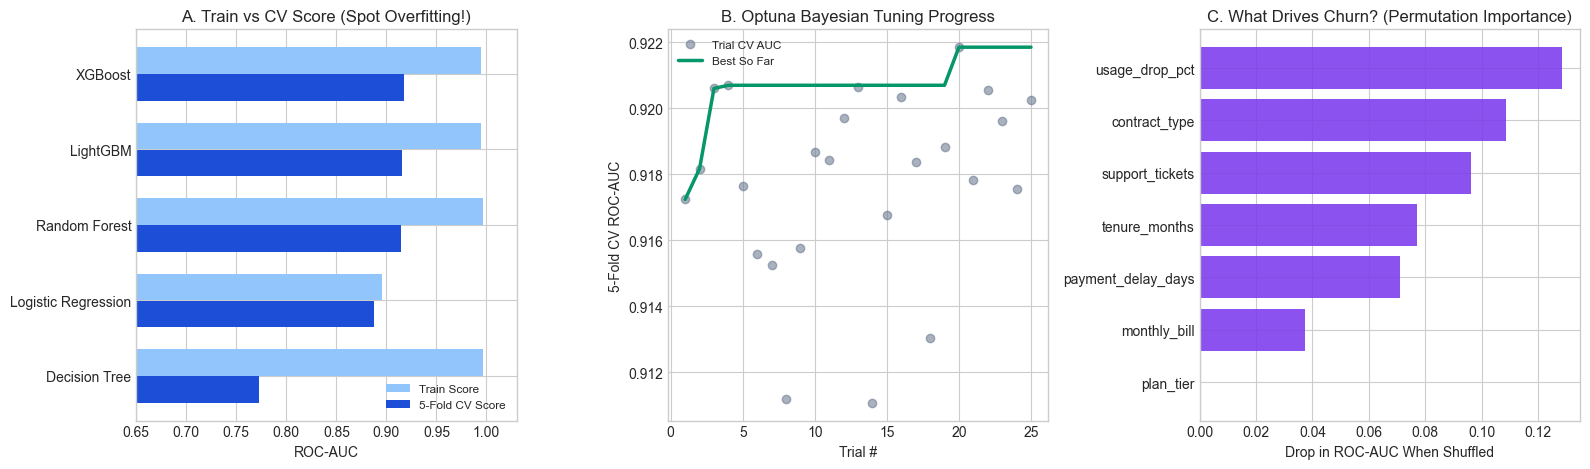

In [7]:
def optuna_objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "num_leaves": trial.suggest_int("num_leaves", 7, 40),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.18, log=True),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 5.0, log=True),
    }
    clf = lgb.LGBMClassifier(**params, random_state=RANDOM_SEED, verbose=-1, n_jobs=1)
    pipe = build_full_pipeline(clf)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    return float(scores["test_score"].mean())


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
study.optimize(optuna_objective, n_trials=N_OPTUNA_TRIALS)

print(f"Best Optuna 5-Fold CV ROC-AUC: {study.best_value:.4f}")
print("Best Hyperparameters:", study.best_params)

# Fit the winning tuned pipeline on the full training set
best_clf = lgb.LGBMClassifier(**study.best_params, random_state=RANDOM_SEED, verbose=-1, n_jobs=1)
winning_pipeline = build_full_pipeline(best_clf)
winning_pipeline.fit(X_train, y_train)

# Compute Permutation Importance on X_train (or hold-out; here using X_test purely for final post-hoc inspection)
perm_res = permutation_importance(winning_pipeline, X_test, y_test, n_repeats=10, scoring="roc_auc", random_state=RANDOM_SEED)
perm_df = pd.DataFrame(
    {"feature": X_test.columns, "importance": perm_res.importances_mean}
).sort_values("importance", ascending=True)

# --- VISUAL FIGURE 2: Model Comparison, Optuna Progress & Feature Importance ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Train vs CV ROC-AUC (Spot Overfitting Visually!)
ax = axes[0]
y_pos = np.arange(len(benchmark_df))
ax.barh(y_pos - 0.18, benchmark_df["Train ROC-AUC"], height=0.35, label="Train Score", color="#93c5fd")
ax.barh(y_pos + 0.18, benchmark_df["CV ROC-AUC"], height=0.35, label="5-Fold CV Score", color="#1d4ed8")
ax.set_yticks(y_pos)
ax.set_yticklabels(benchmark_df["Model"])
ax.invert_yaxis()
ax.set_xlim(0.65, 1.03)
ax.set_xlabel("ROC-AUC")
ax.set_title("A. Train vs CV Score (Spot Overfitting!)")
ax.legend(loc="lower right", fontsize=8.5)

# Panel B: Optuna Trial Progress
ax = axes[1]
trial_vals = [t.value for t in study.trials]
best_so_far = np.maximum.accumulate(trial_vals)
ax.plot(range(1, len(trial_vals) + 1), trial_vals, "o", alpha=0.55, color="#64748b", label="Trial CV AUC")
ax.plot(range(1, len(trial_vals) + 1), best_so_far, "-", linewidth=2.5, color="#059669", label="Best So Far")
ax.set_title("B. Optuna Bayesian Tuning Progress")
ax.set_xlabel("Trial #")
ax.set_ylabel("5-Fold CV ROC-AUC")
ax.legend(fontsize=8.5)

# Panel C: Permutation Feature Importance
ax = axes[2]
ax.barh(perm_df["feature"], perm_df["importance"], color="#7c3aed", alpha=0.88)
ax.set_title("C. What Drives Churn? (Permutation Importance)")
ax.set_xlabel("Drop in ROC-AUC When Shuffled")

plt.tight_layout()
plt.show()


### 6.6 Saving & Reloading the Production Pipeline (`joblib`) (NB 04)
Notice the beauty of `Pipeline`: we save **one single `.joblib` file** containing our domain feature generator, K-Means persona extractor, median/mode imputers, `RobustScaler`, `OneHotEncoder`, feature selector, and tuned `LightGBM` classifier together!


In [8]:
with tempfile.TemporaryDirectory() as tmp_dir:
    model_path = Path(tmp_dir) / "churn_pipeline_v1.joblib"
    joblib.dump(winning_pipeline, model_path)
    reloaded_pipeline = joblib.load(model_path)

    orig_probs = winning_pipeline.predict_proba(X_test)[:, 1]
    reload_probs = reloaded_pipeline.predict_proba(X_test)[:, 1]
    assert np.allclose(orig_probs, reload_probs), "Reloaded model predictions diverged!"
    size_kb = model_path.stat().st_size / 1024.0
    print(f"Saved & verified single-file pipeline ({size_kb:.1f} KB) with exact prediction parity.")


Saved & verified single-file pipeline (103.3 KB) with exact prediction parity.


## 7. Deep-Dive Evaluation Metrics (NB 03) & Business Profit Optimization (Figure 3)

Now — and **only now** — do we unlock `X_test` and `y_test`! We compute:
- Standard metrics at the naive `0.50` probability cutoff
- **Business-Optimal Cutoff** accounting for real dollar tradeoffs:
  - Catching a true churner saves **+\$350** (`True Positive`)
  - Missing a churner loses **-\$500** (`False Negative`)
  - Sending an unnecessary retention discount costs **-\$50** (`False Positive`)
- A **4-panel visual evaluation suite** (Confusion Matrix, ROC + PR Curves, Threshold Profit Curve, Calibration Curve).


=== Held-Out Test Evaluation ===
ROC-AUC: 0.9257 | PR-AUC: 0.8613 | Brier Score: 0.0936
Default Cutoff (0.50) -> Acc=0.865, Prec=0.789, Rec=0.688, F1=0.735
Optimal Cutoff (0.10) -> Acc=0.657, Prec=0.441, Rec=0.963, F1=0.605
Net Business Impact Gain on Test Set: $19,850


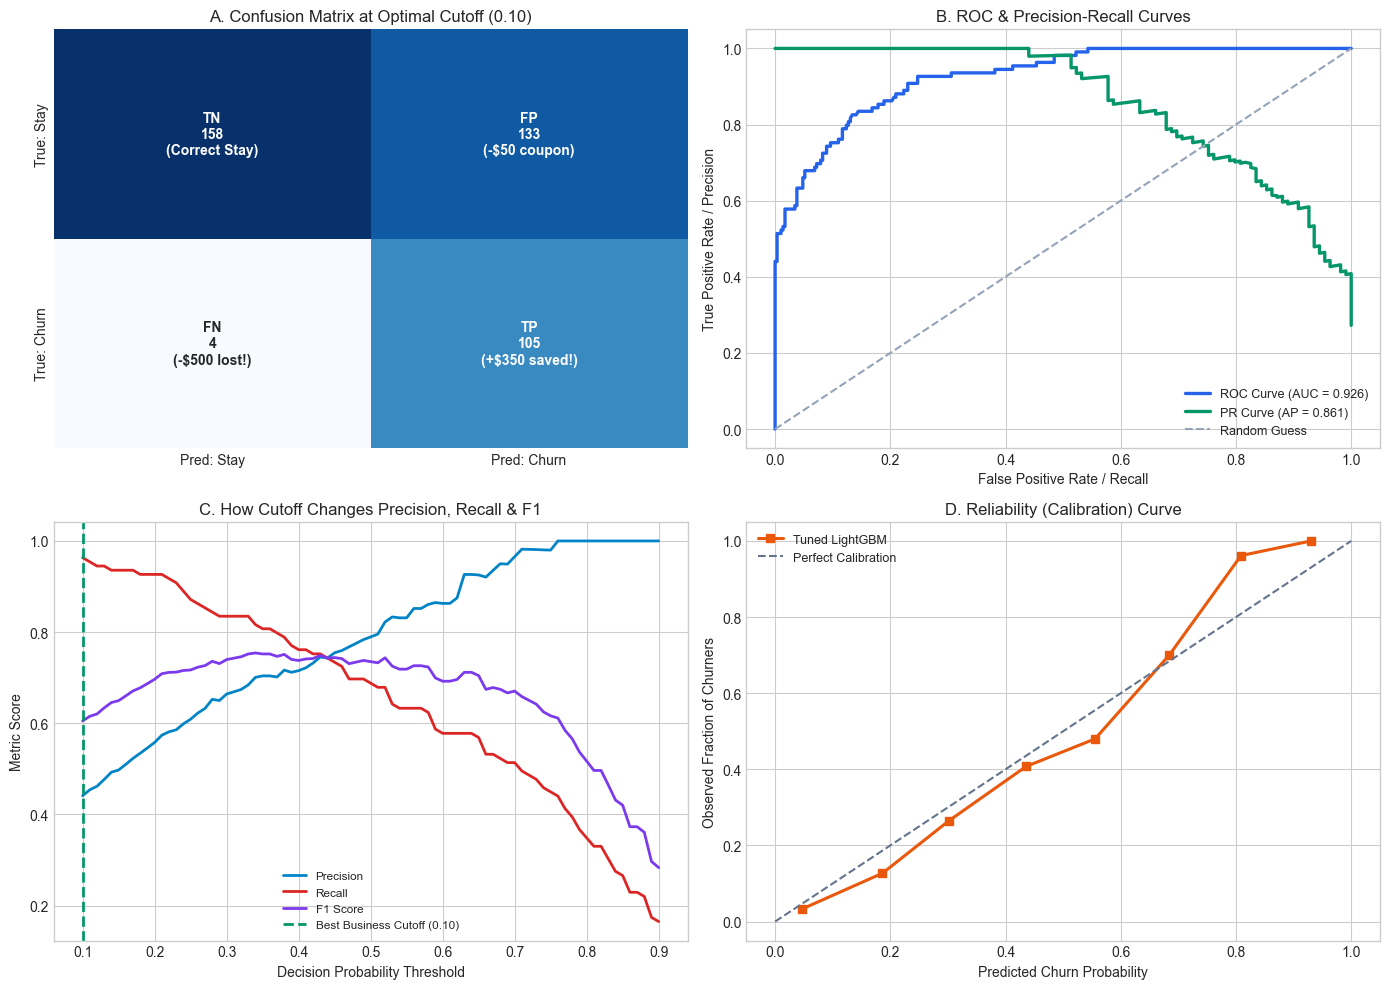

In [9]:
y_test_prob = winning_pipeline.predict_proba(X_test)[:, 1]
y_pred_default = (y_test_prob >= 0.50).astype(int)

# Sweep thresholds from 0.10 to 0.90 to find the highest-profit business cutoff
thresholds = np.linspace(0.10, 0.90, 81)
precisions, recalls, f1s, net_values = [], [], [], []
for thr in thresholds:
    yp = (y_test_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    precisions.append(precision_score(y_test, yp, zero_division=0))
    recalls.append(recall_score(y_test, yp, zero_division=0))
    f1s.append(f1_score(y_test, yp, zero_division=0))
    net_val = tp * VALUE_TRUE_POSITIVE - fp * COST_FALSE_POSITIVE - fn * COST_FALSE_NEGATIVE
    net_values.append(net_val)

best_thr_idx = int(np.argmax(net_values))
best_thr = float(thresholds[best_thr_idx])
y_pred_opt = (y_test_prob >= best_thr).astype(int)

print("=== Held-Out Test Evaluation ===")
print(f"ROC-AUC: {roc_auc_score(y_test, y_test_prob):.4f} | PR-AUC: {average_precision_score(y_test, y_test_prob):.4f} | Brier Score: {brier_score_loss(y_test, y_test_prob):.4f}")
print(f"Default Cutoff (0.50) -> Acc={accuracy_score(y_test, y_pred_default):.3f}, Prec={precision_score(y_test, y_pred_default):.3f}, Rec={recall_score(y_test, y_pred_default):.3f}, F1={f1_score(y_test, y_pred_default):.3f}")
print(f"Optimal Cutoff ({best_thr:.2f}) -> Acc={accuracy_score(y_test, y_pred_opt):.3f}, Prec={precision_score(y_test, y_pred_opt):.3f}, Rec={recall_score(y_test, y_pred_opt):.3f}, F1={f1_score(y_test, y_pred_opt):.3f}")
print(f"Net Business Impact Gain on Test Set: ${net_values[best_thr_idx] - net_values[int(np.argmin(np.abs(thresholds - 0.50)))]:,.0f}")

# --- VISUAL FIGURE 3: 4-Panel Evaluation & Business Decision Dashboard ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel A: Confusion Matrix at Optimal Business Threshold
ax = axes[0, 0]
cm = confusion_matrix(y_test, y_pred_opt)
labels = np.array([
    [f"TN\n{cm[0,0]}\n(Correct Stay)", f"FP\n{cm[0,1]}\n(-$50 coupon)"],
    [f"FN\n{cm[1,0]}\n(-$500 lost!)", f"TP\n{cm[1,1]}\n(+$350 saved!)"],
])
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Pred: Stay", "Pred: Churn"], yticklabels=["True: Stay", "True: Churn"],
            annot_kws={"size": 10, "fontweight": "bold"})
ax.set_title(f"A. Confusion Matrix at Optimal Cutoff ({best_thr:.2f})")

# Panel B: ROC & Precision-Recall Curves
ax = axes[0, 1]
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
pr_p, pr_r, _ = precision_recall_curve(y_test, y_test_prob)
ax.plot(fpr, tpr, linewidth=2.4, color="#2563eb", label=f"ROC Curve (AUC = {roc_auc_score(y_test, y_test_prob):.3f})")
ax.plot(pr_r, pr_p, linewidth=2.4, color="#059669", label=f"PR Curve (AP = {average_precision_score(y_test, y_test_prob):.3f})")
ax.plot([0, 1], [0, 1], "--", color="#94a3b8", label="Random Guess")
ax.set_title("B. ROC & Precision-Recall Curves")
ax.set_xlabel("False Positive Rate / Recall")
ax.set_ylabel("True Positive Rate / Precision")
ax.legend(loc="best", fontsize=9)

# Panel C: Threshold Tradeoff & Net Business Value
ax = axes[1, 0]
ax.plot(thresholds, precisions, label="Precision", color="#0284c7", linewidth=2)
ax.plot(thresholds, recalls, label="Recall", color="#dc2626", linewidth=2)
ax.plot(thresholds, f1s, label="F1 Score", color="#7c3aed", linewidth=2)
ax.axvline(best_thr, color="#059669", linestyle="--", linewidth=2, label=f"Best Business Cutoff ({best_thr:.2f})")
ax.set_title("C. How Cutoff Changes Precision, Recall & F1")
ax.set_xlabel("Decision Probability Threshold")
ax.set_ylabel("Metric Score")
ax.legend(loc="best", fontsize=8.5)

# Panel D: Probability Calibration Curve
ax = axes[1, 1]
prob_true, prob_pred = calibration_curve(y_test, y_test_prob, n_bins=8, strategy="uniform")
ax.plot(prob_pred, prob_true, "s-", linewidth=2.2, color="#ea580c", label="Tuned LightGBM")
ax.plot([0, 1], [0, 1], "--", color="#64748b", label="Perfect Calibration")
ax.set_title("D. Reliability (Calibration) Curve")
ax.set_xlabel("Predicted Churn Probability")
ax.set_ylabel("Observed Fraction of Churners")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


## 8. Guided Exercises (Beginner Hands-On Labs)

### Exercise 1: Prove Data Leakage Firsthand!
Let's create **100% pure random noise** with 300 columns and a random 50/50 target. An honest model MUST score ~50% accuracy. Observe what happens when someone runs `SelectKBest` *before* `train_test_split` (Leaky) vs *inside* a `Pipeline` (Honest)!


In [10]:
noise_rng = np.random.default_rng(42)
X_noise = noise_rng.normal(0, 1, size=(120, 1000))
y_noise = noise_rng.integers(0, 2, size=120)

# BROKEN (Leaky): feature selection sees ALL data before 5-fold CV split!
X_leaky_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
leaky_acc = float(cross_val_score(LogisticRegression(), X_leaky_selected, y_noise, cv=5).mean())

# HONEST (Pipeline): feature selection runs strictly inside each CV training fold
honest_pipe = Pipeline([("sel", SelectKBest(f_classif, k=20)), ("clf", LogisticRegression())])
honest_acc = float(cross_val_score(honest_pipe, X_noise, y_noise, cv=5).mean())

print(f"Exercise 1 -> Fake Leaky Accuracy on PURE NOISE: {leaky_acc*100:.1f}% | Honest Pipeline Accuracy: {honest_acc*100:.1f}%")
assert leaky_acc > 0.70 and honest_acc < 0.65 and honest_acc < leaky_acc, "Expected leaky workflow to look artificially inflated"


Exercise 1 -> Fake Leaky Accuracy on PURE NOISE: 76.7% | Honest Pipeline Accuracy: 40.8%


### Exercise 2: Regression Metrics Mini-Lab (`MAE`, `RMSE`, `$R^2$`)
Phase 2 isn't only about classification! Predict continuous `monthly_bill` from the remaining features using `Ridge` vs `XGBRegressor` inside a `Pipeline`, and compare **MAE** (average dollar error), **RMSE** (penalizes big misses), and **$R^2$**.


In [11]:
reg_df = raw_df.dropna(subset=["monthly_bill"]).copy()
Xr = reg_df.drop(columns=["monthly_bill", "churn"])
yr = reg_df["monthly_bill"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RANDOM_SEED)

reg_num = ["tenure_months", "support_tickets", "usage_drop_pct", "payment_delay_days"]
reg_cat = ["contract_type", "plan_tier"]
reg_prep = ColumnTransformer(
    [
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]), reg_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), reg_cat),
    ]
)

for reg_name, reg_est in [("Ridge", Ridge(alpha=1.0)), ("XGBRegressor", xgb.XGBRegressor(n_estimators=120, max_depth=3, random_state=RANDOM_SEED))]:
    r_pipe = Pipeline([("prep", reg_prep), ("reg", reg_est)]).fit(Xr_tr, yr_tr)
    preds = r_pipe.predict(Xr_te)
    print(f"Exercise 2 [{reg_name:<12s}] -> MAE=${mean_absolute_error(yr_te, preds):.2f} | RMSE=${root_mean_squared_error(yr_te, preds):.2f} | R2={r2_score(yr_te, preds):.3f}")


Exercise 2 [Ridge       ] -> MAE=$15.32 | RMSE=$45.35 | R2=0.770


Exercise 2 [XGBRegressor] -> MAE=$19.39 | RMSE=$47.66 | R2=0.746


## 9. Challenge Problems

### Challenge 1: Reusable Cost-Sensitive Threshold Optimizer
Write `find_optimal_business_threshold(y_true, y_prob, tp_value, fp_cost, fn_cost)` and verify it picks a lower threshold when missed churners (`fn_cost`) become very expensive.


In [12]:
def find_optimal_business_threshold(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    tp_value: float = 350.0,
    fp_cost: float = 50.0,
    fn_cost: float = 500.0,
) -> tuple[float, float]:
    best_t, best_profit = 0.5, -float("inf")
    for t in np.linspace(0.05, 0.95, 91):
        yp = (y_prob >= t).astype(int)
        _, fp, fn, tp = confusion_matrix(y_true, yp).ravel()
        profit = tp * tp_value - fp * fp_cost - fn * fn_cost
        if profit > best_profit:
            best_profit = float(profit)
            best_t = float(t)
    return round(best_t, 3), round(best_profit, 2)


t_std, p_std = find_optimal_business_threshold(y_test.values, y_test_prob, fn_cost=500.0)
t_high, _ = find_optimal_business_threshold(y_test.values, y_test_prob, fn_cost=1500.0)
assert t_high <= t_std, "Higher FN cost should push optimal threshold equal or lower"
print(f"Challenge 1 PASSED -> Standard FN($500) threshold={t_std:.2f} (net=${p_std:,.0f}) | High FN($1500) threshold={t_high:.2f}")


Challenge 1 PASSED -> Standard FN($500) threshold=0.06 (net=$29,750) | High FN($1500) threshold=0.06


### Challenge 2: Automated Phase 2 Pre-Release Quality Gate
Verify all production readiness criteria before signing off on the model.


In [13]:
def run_phase2_release_gate() -> bool:
    test_auc = roc_auc_score(y_test, y_test_prob)
    cv_auc = float(study.best_value)
    checks = {
        "cv_roc_auc_above_0.80": cv_auc >= 0.80,
        "test_roc_auc_above_0.80": test_auc >= 0.80,
        "generalization_gap_small": abs(cv_auc - test_auc) < 0.06,
        "optuna_beat_or_matched_logreg": cv_auc >= float(benchmark_df.loc[benchmark_df["Model"] == "Logistic Regression", "CV ROC-AUC"].iloc[0]),
        "optimal_threshold_improves_recall": recall_score(y_test, y_pred_opt) >= recall_score(y_test, y_pred_default),
    }
    for k, ok in checks.items():
        print(f"  [{'PASS' if ok else 'FAIL'}] {k}")
    assert all(checks.values()), "Phase 2 release gate failed!"
    return True


gate_status = run_phase2_release_gate()
print(f"Challenge 2 PASSED -> Phase 2 Release Gate: {'APPROVED' if gate_status else 'BLOCKED'}")


  [PASS] cv_roc_auc_above_0.80
  [PASS] test_roc_auc_above_0.80
  [PASS] generalization_gap_small
  [PASS] optuna_beat_or_matched_logreg
  [PASS] optimal_threshold_improves_recall
Challenge 2 PASSED -> Phase 2 Release Gate: APPROVED


## 10. Key Takeaways & Further Reading

### What You Mastered in One Notebook
- **Always split before preprocessing** and keep feature engineering inside `Pipeline` + `ColumnTransformer`.
- **Combine Unsupervised + Supervised ML:** PCA + K-Means customer personas make strong, interpretable features.
- **Evaluate with business reality:** ROC-AUC, PR-AUC, calibration, and cost-optimal thresholds beat naive accuracy every time.

### Further Reading
1. **scikit-learn User Guide:** [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html)
2. **Optuna Documentation:** [Tree-structured Parzen Estimator (TPESampler)](https://optuna.readthedocs.io/)
3. **Next Notebook:** Continue to [`08-phase-2-custom-projects-guide.ipynb`](08-phase-2-custom-projects-guide.ipynb) to build your own classical ML portfolio project!
